# T18. Modelo de tarifa e ingresos

**Objetivo.** Verificar la tarifa del CSV y estimar el importe nominal de los viajes observados, por día y periodo.

**Valor para el proyecto.** Cuantificar cómo afectan los registros excluidos a los importes de referencia. El precio por viaje permite valorar la demanda atendida más adelante con los mismos supuestos de tarifa.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import display

from comun.config import cargar_config, carpeta_tablas
from comun.datos import cargar_viajes
from comun.figuras import guardar_figura, plt
from comun.web import exportar

TEMA = "exploracion"
TABLAS = carpeta_tablas(TEMA)
cfg = cargar_config()
limpieza = cfg["limpieza"]
tarifa = limpieza["tarifa"]
desbloqueo = tarifa["desbloqueo_eur"]
minuto = tarifa["minuto_eur"]
tolerancia = limpieza["tolerancia_precio_eur"]

viajes = cargar_viajes(solo_elegibles=False)
viajes["fecha"] = viajes["tsO"].dt.tz_convert(cfg["datos"]["zona_horaria"]).dt.date
viajes["tiempo_eur"] = minuto * viajes["tt_s"] / 60
viajes["error_eur"] = (viajes["price_eur"] - desbloqueo - viajes["tiempo_eur"]).abs()
viajes["larga"] = viajes["tt_s"].gt(limpieza["tt_max_s"])

## 1. Tarifa y efecto del filtro

**Qué queremos ver.** El error absoluto de la regla `precio = desbloqueo + €/min × segundos / 60` y la diferencia de importe entre todos los registros y los viajes elegibles.

**Por qué importa.** La duración anómala puede inflar la suma de precios. La comprobación usa todos los registros y el cálculo operativo usa la misma muestra que las demás fases.

In [2]:
fechas = {
    periodo: pd.date_range(inicio, fin, freq="D")
    for periodo, (inicio, fin) in cfg["datos"]["periodos"].items()
}
fechas["mes"] = fechas["ajuste"].union(fechas["reservada"])

filas = []
for periodo, dias in fechas.items():
    muestra = viajes if periodo == "mes" else viajes.loc[viajes["periodo"].eq(periodo)]
    validos = muestra.loc[muestra["elegible"]]
    total = muestra["price_eur"].sum()
    importe = validos["price_eur"].sum()
    descartado = muestra.loc[~muestra["elegible"], "price_eur"].sum()
    fijo = len(validos) * desbloqueo
    variable = validos["tiempo_eur"].sum()
    largos = muestra.loc[muestra["larga"]]
    assert np.isclose(total, importe + descartado)
    assert abs(importe - fijo - variable) <= validos["error_eur"].sum() + 1e-7
    filas.append({
        "periodo": periodo, "dias": len(dias), "viajes_csv": len(muestra), "viajes_elegibles": len(validos),
        "importe_csv_eur": total, "importe_elegible_eur": importe, "importe_excluido_eur": descartado,
        "pct_importe_excluido": 100 * descartado / total if total else np.nan,
        "viajes_largos": len(largos), "importe_viajes_largos_eur": largos["price_eur"].sum(),
        "importe_desbloqueo_eur": fijo, "importe_tiempo_eur": variable,
        "importe_elegible_dia_eur": importe / len(dias),
        "precio_medio_elegible_eur": validos["price_eur"].mean(),
        "precio_mediano_elegible_eur": validos["price_eur"].median(),
        "precio_p90_elegible_eur": validos["price_eur"].quantile(0.9),
        "error_abs_max_eur": muestra["error_eur"].max(),
        "precios_fuera_tolerancia": int(muestra["error_eur"].gt(tolerancia).sum()),
    })
resumen = pd.DataFrame(filas).round(6)
resumen.to_csv(TABLAS / "T18_resumen.csv", index=False, lineterminator="\n")
display(resumen[["periodo", "viajes_elegibles", "importe_csv_eur", "importe_elegible_eur",
                 "pct_importe_excluido", "error_abs_max_eur", "precios_fuera_tolerancia"]])

,periodo,viajes_elegibles,importe_csv_eur,importe_elegible_eur,pct_importe_excluido,error_abs_max_eur,precios_fuera_tolerancia
0,ajuste,16710,51335.325,44198.6725,13.902030,0.0,0
1,reservada,6582,25084.240,17842.0050,28.871654,0.0,0
2,mes,23292,76419.565,62040.6775,18.815715,0.0,0


**Conclusiones.** La última columna audita la tarifa con la tolerancia de T10. La diferencia entre el importe del CSV y el elegible mide el efecto de la limpieza, y la fila de viajes largos permite identificar cuánto corresponde a duraciones por encima del umbral. El CSV no contiene ajustes comerciales ni cobros efectivos.

## 2. Importe diario y composición

**Qué queremos ver.** El importe nominal elegible por día, separado en desbloqueo y tiempo. La fecha corresponde a la salida en Roma.

**Por qué importa.** Separar los componentes permite distinguir el efecto del número de viajes del efecto de su duración.

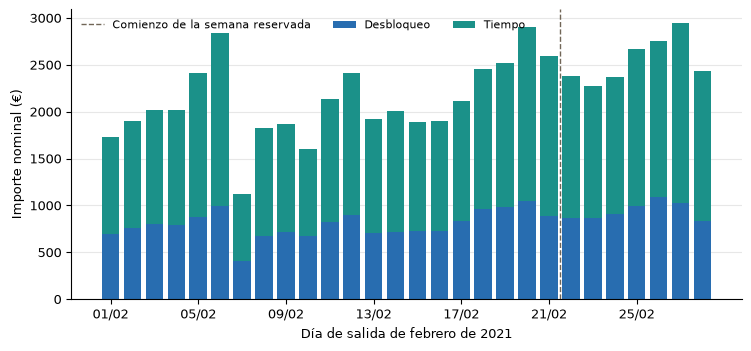

In [3]:
totales = viajes.groupby(["fecha", "periodo"])["price_eur"].sum().rename("importe_csv_eur")
validos = viajes.loc[viajes["elegible"]]
diario = (validos.groupby(["fecha", "periodo"])
          .agg(viajes_elegibles=("price_eur", "size"), importe_elegible_eur=("price_eur", "sum"),
               importe_tiempo_eur=("tiempo_eur", "sum"))
          .reindex(totales.index, fill_value=0).join(totales).reset_index())
diario["importe_desbloqueo_eur"] = desbloqueo * diario["viajes_elegibles"]
diario["importe_excluido_eur"] = diario["importe_csv_eur"] - diario["importe_elegible_eur"]
assert np.isclose(diario["importe_elegible_eur"].sum(), validos["price_eur"].sum())
diario = diario.round(6)
diario.to_csv(TABLAS / "T18_ingresos_diarios.csv", index=False, lineterminator="\n")

fig, eje = plt.subplots(figsize=(7.4, 3.4), layout="constrained")
x = pd.to_datetime(diario["fecha"])
eje.bar(x, diario["importe_desbloqueo_eur"], color="#286db0", label="Desbloqueo")
eje.bar(x, diario["importe_tiempo_eur"], bottom=diario["importe_desbloqueo_eur"],
        color="#1b9189", label="Tiempo")
eje.axvline(fechas["reservada"][0] - pd.Timedelta(hours=12), color="#716657", linestyle="--", lw=1,
            label="Comienzo de la semana reservada")
eje.set(ylabel="Importe nominal (€)", xlabel="Día de salida de febrero de 2021", axisbelow=True)
eje.set_xticks(x.iloc[::4], labels=x.iloc[::4].dt.strftime("%d/%m").tolist())
eje.legend(frameon=False, ncol=3, loc="upper left")
eje.grid(axis="x", visible=False)
guardar_figura(fig, TEMA, "T18_importe_diario")

exportar("fase0", "t18_tarifa", {
    "tarifa": tarifa, "resumen": resumen, "diario": diario,
    "inicio_reservada": fechas["reservada"][0].date(),
})

**Conclusiones.** Las barras usan los mismos viajes elegibles que los indicadores de movilidad. El desglose temporal permite trasladar el modelo al simulador por viaje atendido, manteniendo una demanda fija. Para valorar beneficios harían falta costes, descuentos, impuestos y cobros reales.